# Question 4: Food prices and food shelf activity

Do more people arrive at food shelves when grocery prices rise? Does the response happen at once, or is there a delay? Does the response appear in all three of the food shelf metrics? Are there other cyclical patterns that prices do not explain?
Understanding the timing enables The Food Group to communicate expected changes in demand to food shelves and expected need to donors.

Datasets:
 File | Grain | Role |
|---|---|---|
| `org_FSStats.xlsx` | Site × month | Monthly food-shelf visits and pounds distributed |
| `Q4-FRED-CPI-Midwest.xlsx` | (?) | Midwest Region Monthly Food Price Index (CPI) |

### Setup & Inspect

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

FS_PATH = "org_FSStats.xlsx"
CPI_PATH = "Q4-FRED-CPI-Midwest.xlsx"

fs_raw = pd.read_excel(FS_PATH, sheet_name="org_FSStats")
cpi_raw = pd.read_excel(CPI_PATH, sheet_name="Monthly")

print("FSStats shape:", fs_raw.shape)
print("FSStats columns:", fs_raw.columns.tolist())
print()
print("CPI shape:", cpi_raw.shape)
print(cpi_raw.tail())

FSStats shape: (28287, 58)
FSStats columns: ['__ID', '_id_site', '_Year', '_Month', 'DateForSearch', 'zzCreationTS', 'zzModificationTS', 'AdultsReg', 'ChildrenReg', 'HouseholdsReg', 'IndividualsReg', 'Meals', 'Misc', 'People', 'PoundsReg', 'SeniorsReg', 'Snacks', 'UniqueVisitsReg', 'County', 'FederalDistrict', 'StateDistrict', 'FoodBank', 'ChildrenExtra', 'ChildrenProduce', 'ChildrenHoliday', 'AdultsExtra', 'AdultsProduce', 'AdultsHoliday', 'IndividualsExtra', 'SeniorsExtra', 'SeniorsProduce', 'SeniorsHoliday', 'IndividualsProduce', 'IndividualsHoliday', 'UniqueVisitsExtra', 'UniqueVisitsProduce', 'UniqueVisitsHoliday', 'UniqueVisitsTotal', 'SeniorsTotal', 'IndividualsTotal', 'ChildrenTotal', 'AdultsTotal', 'HouseholdsExtra', 'HouseholdsProduce', 'HouseholdsHoliday', 'HouseholdsTotal', 'PoundsExtra', 'PoundsProduce', 'PoundsHoliday', 'PoundsTotal', 'AgencyType', '_id_bank', 'SuperShelf', '_YearMonth', 'PoundsPerIndiv', 'IndividualsPerHH', 'id_agency', 'PoundsPerHH']

CPI shape: (585, 2

### Apply the August 2026 Rule

In [3]:
# Competition rule: never use August data, from any source, for any reason.
# Truncate both datasets at July 2026 immediately after loading.

cpi_raw["observation_date"] = pd.to_datetime(cpi_raw["observation_date"])
cpi = cpi_raw[cpi_raw["observation_date"] <= "2026-07-31"].copy()

print("CPI last date after truncation:", cpi["observation_date"].max())
assert cpi["observation_date"].max() <= pd.Timestamp("2026-07-31"), "August data leaked in!"

CPI last date after truncation: 2026-07-01 00:00:00


### Crosswalk: County Label Organization

In [4]:
# FSStats splits some counties into sub-regions. Standardize to one label per county
# so it can later join with CPI/SNAP/MMG data (which use plain county names).

county_crosswalk = {
    "Hennepin-Minneapolis": "Hennepin",
    "Hennepin-Suburbs": "Hennepin",
    "Ramsey-Saint Paul": "Ramsey",
    "Ramsey-Suburbs": "Ramsey",
    # add more here if the printed county list in Cell 1 shows other split labels
    # e.g. "St. Louis" vs "Saint Louis" duplicates
}

fs = fs_raw.copy()
fs["County_clean"] = fs["County"].replace(county_crosswalk)

print("Unique counties before:", fs_raw["County"].nunique())
print("Unique counties after:", fs["County_clean"].nunique())

Unique counties before: 91
Unique counties after: 87


### Outlier Handling (households typo)

In [5]:
# Known data-entry errors from earlier EDA:
#   - Waseca, July 2023: HouseholdsReg reported as ~273,385 (vs ~646 individuals)
#   - Ramsey-Suburbs, March 2025: HouseholdsReg reported as ~83,909 (vs ~13,735 individuals)
# Rule: if HouseholdsReg > IndividualsReg (impossible under the glossary definition
# of a visit), treat HouseholdsReg as missing rather than dropping the whole row.

bad_mask = fs["HouseholdsReg"] > fs["IndividualsReg"]
print("Rows flagged as household typos:", bad_mask.sum())
print(fs.loc[bad_mask, ["County_clean", "_Year", "_Month", "HouseholdsReg", "IndividualsReg", "PoundsReg"]])

fs.loc[bad_mask, "HouseholdsReg"] = np.nan

Rows flagged as household typos: 153
      County_clean  _Year  _Month  HouseholdsReg  IndividualsReg  PoundsReg
58        Hennepin   2022       1         3118.0           670.0    15311.0
60        Hennepin   2022       1          158.0           157.0     5250.0
62        Hennepin   2022       1          704.0           686.0    27400.0
154       Hennepin   2022       2          238.0           235.0     4311.0
164       Hennepin   2022       2          294.0           266.0     8720.0
...            ...    ...     ...            ...             ...        ...
27633      Chisago   2026       6          386.0           384.0    15116.0
27781      Stearns   2026       6         1255.0          1252.0    12025.0
27978     Hennepin   2026       7          404.0           403.0    33939.0
28029       Ramsey   2026       7           81.0            57.0     1419.0
28059       Dakota   2026       7         1406.0          1074.0    16553.0

[153 rows x 6 columns]


### Filter AgencyType + Create County x Month Panel

In [9]:
# _Month != 1~12
print(
    panel.loc[
        ~panel["_Month"].between(1, 12),
        ["County_clean", "_Year", "_Month", "visits", "pounds", "individuals"]
    ]
)

     County_clean  _Year  _Month  visits    pounds  individuals
452       Carlton   2023       0   410.0   32701.0       1088.0
838          Cook   2023       0    96.0    6330.0        182.0
2049         Lake   2023       0   387.0   25426.0        862.0
3272         Polk   2023      15    33.0    2043.0         69.0
3921    St. Louis   2023       0  4938.0  343528.0      12098.0


In [10]:
# Keep only food-shelf-like sites. Adjust this list after checking
# fs["AgencyType"].value_counts() from Cell 1's output.
FOOD_SHELF_TYPES = ["Food Shelf", "Brick and Mortar Site"]

fs_filtered = fs[fs["AgencyType"].isin(FOOD_SHELF_TYPES)].copy()

panel = (
    fs_filtered
    .groupby(["County_clean", "_Year", "_Month"], as_index=False)
    .agg(
        visits=("HouseholdsReg", "sum"),
        pounds=("PoundsReg", "sum"),
        individuals=("IndividualsReg", "sum"),
    )
)

# Remove invalid / unknown month values
panel = panel[panel["_Month"].between(1, 12)].copy()

# Create monthly date
panel["date"] = pd.to_datetime(
    panel["_Year"].astype(str) + "-" +
    panel["_Month"].astype(str).str.zfill(2) + "-01"
)

# Keep data through July 2026
panel = panel[panel["date"] <= "2026-07-31"].copy()

print("Panel shape:", panel.shape)
print(panel.head())

Panel shape: (4730, 7)
  County_clean  _Year  _Month  visits   pounds  individuals       date
0       Aitkin   2022       1   222.0  11249.0        547.0 2022-01-01
1       Aitkin   2022       2   222.0  11249.0        547.0 2022-02-01
2       Aitkin   2022       3   234.0  12729.0        562.0 2022-03-01
3       Aitkin   2022       4   297.0  14382.0        597.0 2022-04-01
4       Aitkin   2022       5   236.0  13290.0        593.0 2022-05-01


### Merge CPI into Panel

In [11]:
# CPI is Midwest-region level (not county-specific), so every county in a given
# month gets the same CPI value. This is a documented limitation, not a bug.

cpi["_Year"] = cpi["observation_date"].dt.year
cpi["_Month"] = cpi["observation_date"].dt.month
cpi = cpi.rename(columns={"CUUR0200SAF11": "cpi_food_at_home_midwest"})

merged = panel.merge(cpi[["_Year", "_Month", "cpi_food_at_home_midwest"]], on=["_Year", "_Month"], how="left")

print("Rows with missing CPI after merge:", merged["cpi_food_at_home_midwest"].isna().sum())
merged.head()

Rows with missing CPI after merge: 86


,County_clean,_Year,_Month,visits,pounds,individuals,date,cpi_food_at_home_midwest
0,Aitkin,2022,1,222.0,11249.0,547.0,2022-01-01,255.381
1,Aitkin,2022,2,222.0,11249.0,547.0,2022-02-01,258.599
2,Aitkin,2022,3,234.0,12729.0,562.0,2022-03-01,263.145
3,Aitkin,2022,4,297.0,14382.0,597.0,2022-04-01,267.001
4,Aitkin,2022,5,236.0,13290.0,593.0,2022-05-01,271.278


### Search: The Relationship Between Price and Activity

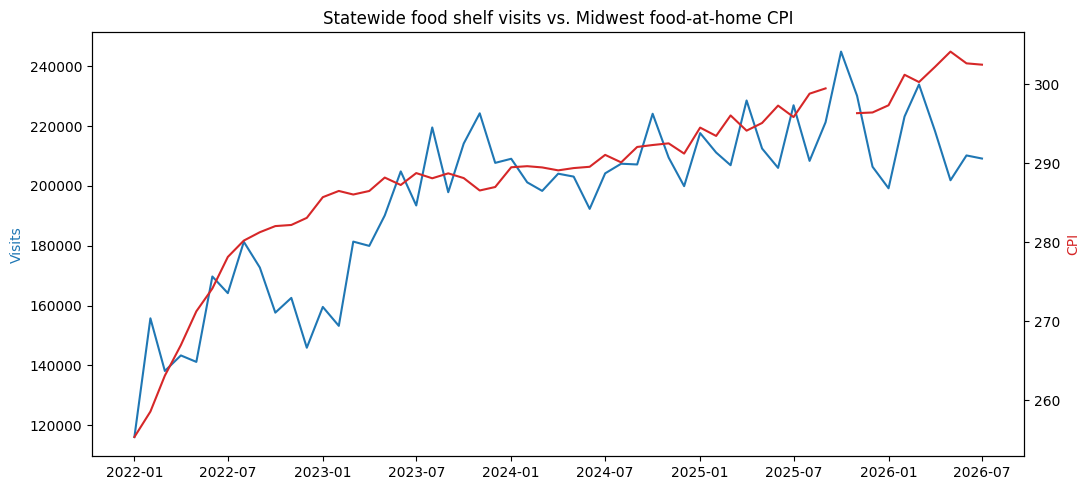

Correlation (visits, CPI): 0.8310264888061786


In [12]:
statewide = merged.groupby("date", as_index=False).agg(
    visits=("visits", "sum"),
    pounds=("pounds", "sum"),
    cpi=("cpi_food_at_home_midwest", "first"),
)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(statewide["date"], statewide["visits"], color="tab:blue", label="Visits (HouseholdsReg)")
ax1.set_ylabel("Visits", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(statewide["date"], statewide["cpi"], color="tab:red", label="CPI: Food at Home (Midwest)")
ax2.set_ylabel("CPI", color="tab:red")
plt.title("Statewide food shelf visits vs. Midwest food-at-home CPI")
fig.tight_layout()
plt.show()

print("Correlation (visits, CPI):", statewide["visits"].corr(statewide["cpi"]))

### Lag Correlation Exploration

In [13]:
# Prices may affect food-shelf demand with a delay. Test a few lags.
for lag in range(0, 4):
    lagged_cpi = statewide["cpi"].shift(lag)
    corr = statewide["visits"].corr(lagged_cpi)
    print(f"lag={lag} month(s): corr(visits, CPI) = {corr:.3f}")

lag=0 month(s): corr(visits, CPI) = 0.831
lag=1 month(s): corr(visits, CPI) = 0.818
lag=2 month(s): corr(visits, CPI) = 0.818
lag=3 month(s): corr(visits, CPI) = 0.801


# **Edited Ver.**

In [ ]:
panel = (
    fs_filtered
    .groupby(["County_clean", "_Year", "_Month"], as_index=False)
    .agg(
        visits=("HouseholdsReg", lambda x: x.sum(min_count=1)),
        pounds=("PoundsReg", lambda x: x.sum(min_count=1)),
        individuals=("IndividualsReg", lambda x: x.sum(min_count=1)),
    )
)

panel = panel[panel["_Month"].between(1, 12)].copy()

In [ ]:
# cpi missing month
analysis = merged.dropna(
    subset=["cpi_food_at_home_midwest"]
).copy()

print("Months used in analysis:", analysis["date"].nunique())
print("Missing CPI months:", merged.loc[
    merged["cpi_food_at_home_midwest"].isna(),
    "date"
].unique())

In [ ]:
# correlation: by monthly change
statewide = (
    merged
    .groupby("date", as_index=False)
    .agg(
        visits=("visits", "sum"),
        pounds=("pounds", "sum"),
        individuals=("individuals", "sum"),
        cpi=("cpi_food_at_home_midwest", "first"),
    )
    .sort_values("date")
)

# Remove the month with missing CPI
statewide = statewide.dropna(subset=["cpi"]).copy()

# Month-to-month percentage changes
for col in ["visits", "individuals", "pounds", "cpi"]:
    statewide[f"{col}_pct_change"] = statewide[col].pct_change() * 100

print(
    statewide[
        [
            "date",
            "visits_pct_change",
            "individuals_pct_change",
            "pounds_pct_change",
            "cpi_pct_change",
        ]
    ].head(10)
)

metrics = ["visits", "individuals", "pounds"]

for metric in metrics:
    corr = statewide[f"{metric}_pct_change"].corr(
        statewide["cpi_pct_change"]
    )
    print(f"{metric}: contemporaneous correlation = {corr:.3f}")

In [ ]:
# any delay?
for metric in ["visits", "individuals", "pounds"]:
    print(f"\n{metric}")

    for lag in range(0, 4):
        corr = statewide[f"{metric}_pct_change"].corr(
            statewide["cpi_pct_change"].shift(lag)
        )
        print(f"  CPI lag {lag} month(s): {corr:.3f}")

In [ ]:
# Does it appear for all 3 metrics?
lag_results = []

for metric in ["visits", "individuals", "pounds"]:
    for lag in range(0, 4):
        corr = statewide[f"{metric}_pct_change"].corr(
            statewide["cpi_pct_change"].shift(lag)
        )

        lag_results.append({
            "metric": metric,
            "CPI_lag_months": lag,
            "correlation": corr
        })

lag_results = pd.DataFrame(lag_results)

lag_results

pivot = lag_results.pivot(
    index="metric",
    columns="CPI_lag_months",
    values="correlation"
)

print(pivot.round(3))

In [ ]:
# Are there other cyclical patterns that prices do not explain?
# monthly avg activity
statewide["month"] = statewide["date"].dt.month

seasonality = (
    statewide
    .groupby("month")
    .agg(
        visits=("visits", "mean"),
        individuals=("individuals", "mean"),
        pounds=("pounds", "mean"),
        cpi=("cpi", "mean"),
    )
)

print(seasonality.round(1))

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    seasonality.index,
    seasonality["visits"],
    marker="o",
    label="Visits"
)

ax.plot(
    seasonality.index,
    seasonality["individuals"],
    marker="o",
    label="Individuals"
)

ax.set_xlabel("Month")
ax.set_ylabel("Average monthly activity")
ax.set_title("Seasonal patterns in food shelf activity")
ax.legend()

plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [ ]:
# better method?
# compare - CPI & seasonality
import statsmodels.formula.api as smf

reg_data = statewide.copy()
reg_data["month"] = reg_data["date"].dt.month

model_visits = smf.ols(
    "visits_pct_change ~ cpi_pct_change + C(month)",
    data=reg_data.dropna()
).fit()

print(model_visits.summary())

# individuals
model_individuals = smf.ols(
    "individuals_pct_change ~ cpi_pct_change + C(month)",
    data=reg_data.dropna()
).fit()

print(model_individuals.summary())

# pounds
model_pounds = smf.ols(
    "pounds_pct_change ~ cpi_pct_change + C(month)",
    data=reg_data.dropna()
).fit()

print(model_pounds.summary())